## **Question 1: Student Performance Prediction**

A college develops a neural network to predict student examination scores using attendance
and internal assessment marks. The model trained using Gradient Descent shows a slow
decrease in loss, while the model trained using SGD shows fluctuations in loss across epochs.
Analyze the training behavior of both optimizers by implementing the models using
TensorFlow and Keras, storing loss values using NumPy, and plotting the loss curves using
Matplotlib. Identify the possible reasons for the differences in convergence.
Packages: NumPy, TensorFlow, Keras, Matplotlib

Final GD loss: 388.7651
Final SGD loss: 19.8782


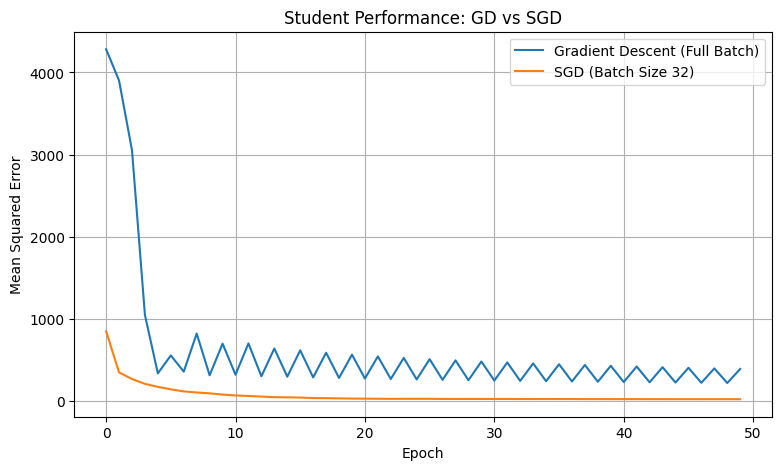

In [ ]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

n = 1000
attendance = np.random.uniform(40, 100, n)
internal_marks = np.random.uniform(20, 100, n)

X = np.column_stack((attendance, internal_marks)).astype("float32")
y = (0.3 * attendance + 0.7 * internal_marks
     + np.random.normal(0, 4, n)).astype("float32")

X = (X - X.mean(axis=0)) / X.std(axis=0)

def build_model():
    return keras.Sequential([
        keras.Input(shape=(2,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(1)
    ])

base = build_model()
initial_weights = base.get_weights()

def train_model(batch_size):
    model = build_model()
    model.set_weights(initial_weights)
    model.compile(
        optimizer=keras.optimizers.SGD(learning_rate=0.01),
        loss="mse"
    )
    history = model.fit(
        X, y, epochs=50, batch_size=batch_size,
        shuffle=False, verbose=0
    )
    return np.array(history.history["loss"])

gd_loss = train_model(len(X))
sgd_loss = train_model(32)

losses = np.column_stack((gd_loss, sgd_loss))
print("Final GD loss:", round(float(gd_loss[-1]), 4))
print("Final SGD loss:", round(float(sgd_loss[-1]), 4))

plt.figure(figsize=(9, 5))
plt.plot(gd_loss, label="Gradient Descent (Full Batch)")
plt.plot(sgd_loss, label="SGD (Batch Size 32)")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Student Performance: GD vs SGD")
plt.legend()
plt.grid(True)
plt.show()


# **Question 2: House Price Prediction**

A real-estate company trains a neural network to predict house prices. During training, the
loss decreases rapidly at first but fluctuates significantly when SGD is used with a high
learning rate. When a smaller learning rate is used, training becomes more stable but slower.
Analyze how the learning rate affects SGD convergence by training the model with different
learning rates using TensorFlow and Keras. Use NumPy to organize the loss values and
Matplotlib to compare the loss curves. Determine which learning-rate setting provides a
better balance between convergence speed and stability.
Packages: NumPy, TensorFlow, Keras, Matplotlib

Learning rate 0.001: Final training loss = 0.22437, Final validation loss = 0.22810
Learning rate 0.01: Final training loss = 0.04413, Final validation loss = 0.04838
Learning rate 0.1: Final training loss = 0.04425, Final validation loss = 0.04623


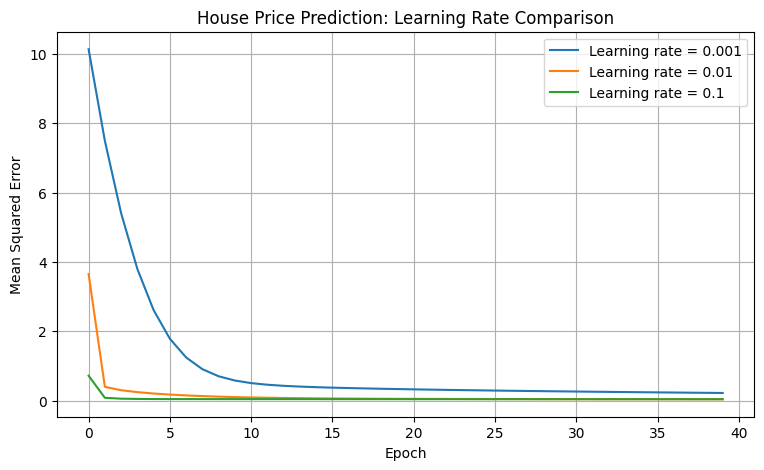

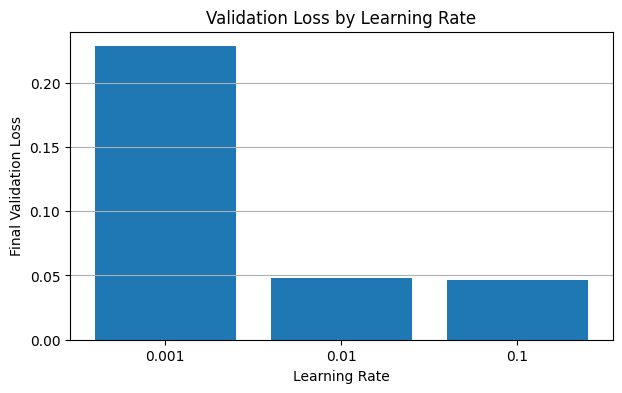

Lowest final validation loss obtained with learning rate: 0.1


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

n = 1200
area = np.random.uniform(500, 3500, n)
bedrooms = np.random.randint(1, 6, n)
age = np.random.uniform(0, 40, n)

X = np.column_stack((area, bedrooms, age)).astype("float32")
y = (50000 + 150 * area + 12000 * bedrooms
     - 900 * age + np.random.normal(0, 20000, n))
y = (y / 100000).astype("float32")


X = (X - X.mean(axis=0)) / X.std(axis=0)

X_train, X_val = X[:1000], X[1000:]
y_train, y_val = y[:1000], y[1000:]

def build_model():
    return keras.Sequential([
        keras.Input(shape=(3,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(1)
    ])

base = build_model()
initial_weights = base.get_weights()

learning_rates = [0.001, 0.01, 0.1]
histories = {}
final_losses = {}

for lr in learning_rates:
    model = build_model()
    model.set_weights(initial_weights)
    model.compile(
        optimizer=keras.optimizers.SGD(learning_rate=lr),
        loss="mse"
    )
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=40, batch_size=32,
        shuffle=False, verbose=0
    )
    histories[lr] = np.array(history.history["loss"])
    final_losses[lr] = history.history["val_loss"][-1]

    print(f"Learning rate {lr}: "
          f"Final training loss = {histories[lr][-1]:.5f}, "
          f"Final validation loss = {final_losses[lr]:.5f}")
plt.figure(figsize=(9, 5))
for lr in learning_rates:
    plt.plot(histories[lr], label=f"Learning rate = {lr}")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("House Price Prediction: Learning Rate Comparison")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.bar([str(lr) for lr in learning_rates],
        [final_losses[lr] for lr in learning_rates])
plt.xlabel("Learning Rate")
plt.ylabel("Final Validation Loss")
plt.title("Validation Loss by Learning Rate")
plt.grid(axis="y")
plt.show()

best_lr = min(final_losses, key=final_losses.get)
print("Lowest final validation loss obtained with learning rate:", best_lr)


# **Question 3: Handwritten Digit Classification**

An image-recognition system uses a neural network to classify handwritten digits. The model
trained with SGD takes longer to reach a low training loss, whereas the model trained with
Momentum converges more quickly.
Analyze the performance differences between SGD and Momentum by training both models
under the same experimental conditions. Use NumPy to compare epoch-wise losses and
Matplotlib to visualize convergence. Explain how Momentum influences updates when
gradients consistently point in a similar direction.
Packages: NumPy, TensorFlow, Keras, Matplotlib

Epoch 1/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3846 - loss: 2.0178 - val_accuracy: 0.5940 - val_loss: 1.7425
Epoch 2/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7131 - loss: 1.4113 - val_accuracy: 0.7205 - val_loss: 1.3108
Epoch 3/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7903 - loss: 1.0373 - val_accuracy: 0.7615 - val_loss: 1.0474
Epoch 4/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8248 - loss: 0.8264 - val_accuracy: 0.7885 - val_loss: 0.8916
Epoch 5/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8455 - loss: 0.7018 - val_accuracy: 0.8060 - val_loss: 0.7923
Epoch 6/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8592 - loss: 0.6213 - val_accuracy: 0.8160 - val_loss: 0.7237
Epoch 7/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8686 - loss: 0.5653 - val_accuracy: 0.8285 - val_loss: 0.6736
Epoch 8/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8744 - loss: 0.5239 - val_accuracy: 0.8360 - val_los

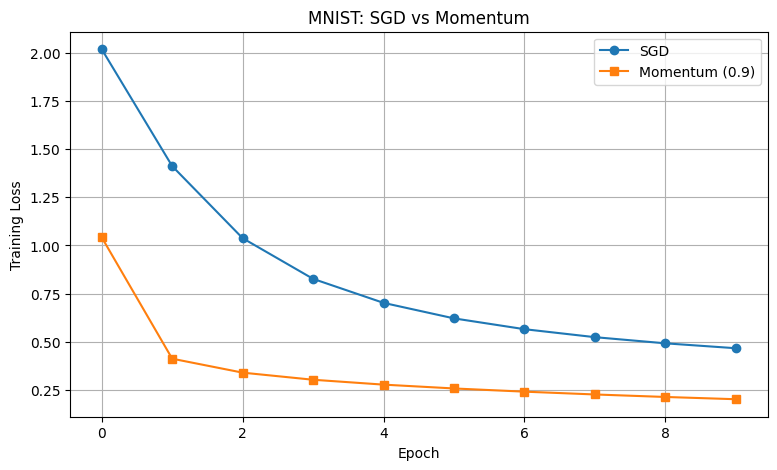

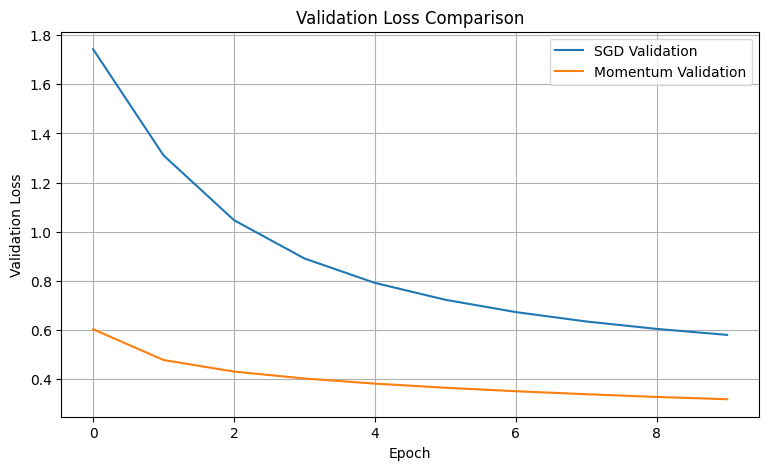

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

X_train = X_train[:12000].astype("float32") / 255.0
y_train = y_train[:12000]
X_test = X_test[:2000].astype("float32") / 255.0
y_test = y_test[:2000]

X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

def build_model():
    return keras.Sequential([
        keras.Input(shape=(784,)),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

base = build_model()
initial_weights = base.get_weights()

def train_model(use_momentum):
    model = build_model()
    model.set_weights(initial_weights)

    if use_momentum:
        optimizer = keras.optimizers.SGD(
            learning_rate=0.01, momentum=0.9
        )
    else:
        optimizer = keras.optimizers.SGD(
            learning_rate=0.01
        )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train, y_train,
        epochs=10, batch_size=128,
        validation_data=(X_test, y_test),
        shuffle=False, verbose=1
    )

    return model, history

sgd_model, sgd_history = train_model(False)
momentum_model, momentum_history = train_model(True)

sgd_loss = np.array(sgd_history.history["loss"])
momentum_loss = np.array(momentum_history.history["loss"])

loss_comparison = np.column_stack((sgd_loss, momentum_loss))

print("\nEpoch-wise training losses")
print("Epoch | SGD Loss | Momentum Loss")
for i, (a, b) in enumerate(loss_comparison, start=1):
    print(f"{i:5d} | {a:.4f}   | {b:.4f}")

sgd_eval = sgd_model.evaluate(X_test, y_test, verbose=0)
momentum_eval = momentum_model.evaluate(X_test, y_test, verbose=0)

print(f"\nSGD Test Accuracy: {sgd_eval[1] * 100:.2f}%")
print(f"Momentum Test Accuracy: {momentum_eval[1] * 100:.2f}%")

plt.figure(figsize=(9, 5))
plt.plot(sgd_loss, marker="o", label="SGD")
plt.plot(momentum_loss, marker="s", label="Momentum (0.9)")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("MNIST: SGD vs Momentum")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(sgd_history.history["val_loss"], label="SGD Validation")
plt.plot(momentum_history.history["val_loss"], label="Momentum Validation")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.grid(True)
plt.show()

# **Question 4: Disease Risk Classification**

A healthcare analytics team builds a neural network to classify patient records into risk
categories. The team observes that Adam reduces training loss quickly, while ordinary
Gradient Descent requires more epochs to achieve a similar loss value.

Analyze the convergence behavior of Gradient Descent and Adam by training comparable
Keras models with TensorFlow. Record the loss values using NumPy and plot the results
using Matplotlib. Evaluate the differences in convergence speed and training stability, and
explain why Adam's adaptive learning rates may be beneficial.
Packages: NumPy, TensorFlow, Keras, Matplotlib

Gradient Descent final training loss: 0.5703
Adam final training loss: 0.4288
Gradient Descent final validation loss: 0.5591
Adam final validation loss: 0.4374


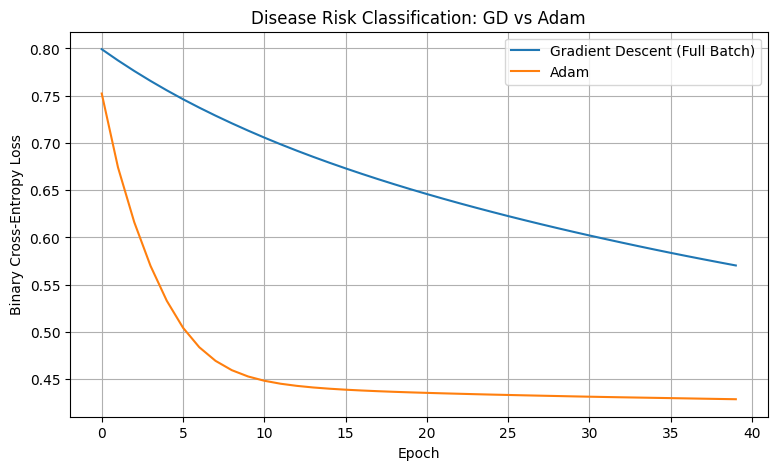

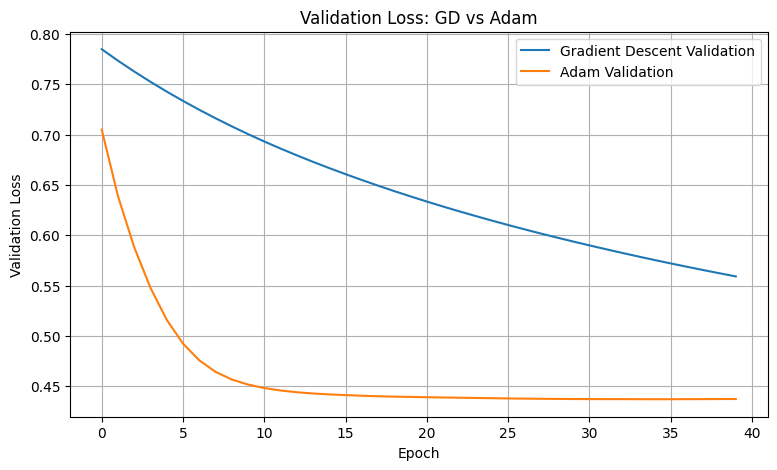

GD Validation Accuracy: 73.25%
Adam Validation Accuracy: 77.25%


In [ ]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)


n = 2000
X = np.random.normal(size=(n, 8)).astype("float32")


scores = (1.5 * X[:, 0] - 1.2 * X[:, 1]
          + 0.8 * X[:, 2] + 0.5 * X[:, 3])
probabilities = 1 / (1 + np.exp(-scores))
y = (np.random.random(n) < probabilities).astype("float32")

X_train, X_val = X[:1600], X[1600:]
y_train, y_val = y[:1600], y[1600:]

def build_model():
    return keras.Sequential([
        keras.Input(shape=(8,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])


base = build_model()
initial_weights = base.get_weights()

def train_model(optimizer, batch_size):
    model = build_model()
    model.set_weights(initial_weights)

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=40, batch_size=batch_size,
        shuffle=False, verbose=0
    )
    return model, history

gd_model, gd_history = train_model(
    keras.optimizers.SGD(learning_rate=0.1),
    batch_size=len(X_train)
)


adam_model, adam_history = train_model(
    keras.optimizers.Adam(learning_rate=0.001),
    batch_size=32
)

gd_loss = np.array(gd_history.history["loss"])
adam_loss = np.array(adam_history.history["loss"])
gd_val_loss = np.array(gd_history.history["val_loss"])
adam_val_loss = np.array(adam_history.history["val_loss"])

print("Gradient Descent final training loss:", round(float(gd_loss[-1]), 4))
print("Adam final training loss:", round(float(adam_loss[-1]), 4))
print("Gradient Descent final validation loss:", round(float(gd_val_loss[-1]), 4))
print("Adam final validation loss:", round(float(adam_val_loss[-1]), 4))

plt.figure(figsize=(9, 5))
plt.plot(gd_loss, label="Gradient Descent (Full Batch)")
plt.plot(adam_loss, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Disease Risk Classification: GD vs Adam")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(gd_val_loss, label="Gradient Descent Validation")
plt.plot(adam_val_loss, label="Adam Validation")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss: GD vs Adam")
plt.legend()
plt.grid(True)
plt.show()

print(f"GD Validation Accuracy: "
      f"{gd_model.evaluate(X_val, y_val, verbose=0)[1] * 100:.2f}%")
print(f"Adam Validation Accuracy: "
      f"{adam_model.evaluate(X_val, y_val, verbose=0)[1] * 100:.2f}%")


# **Question 5: Optimizer Comparison for Sales Forecasting**

A retail company develops a neural network to forecast weekly sales. Four versions of the
model are trained using Gradient Descent, SGD, Momentum and Adam. The models show
different training-loss patterns, convergence speeds and validation performance.
Analyze and compare the four optimizers by training the models using TensorFlow and Keras
under comparable conditions. Use NumPy to store and compare training and validation
losses, and Matplotlib to plot the loss curves. Identify which optimizer provides the most
suitable combination of convergence speed, stability and validation performance, and justify
the selection using experimental evidence.
Packages: NumPy, TensorFlow, Keras, Matplotlib

Gradient Descent: Training complete
SGD: Training complete
Momentum: Training complete
Adam: Training complete


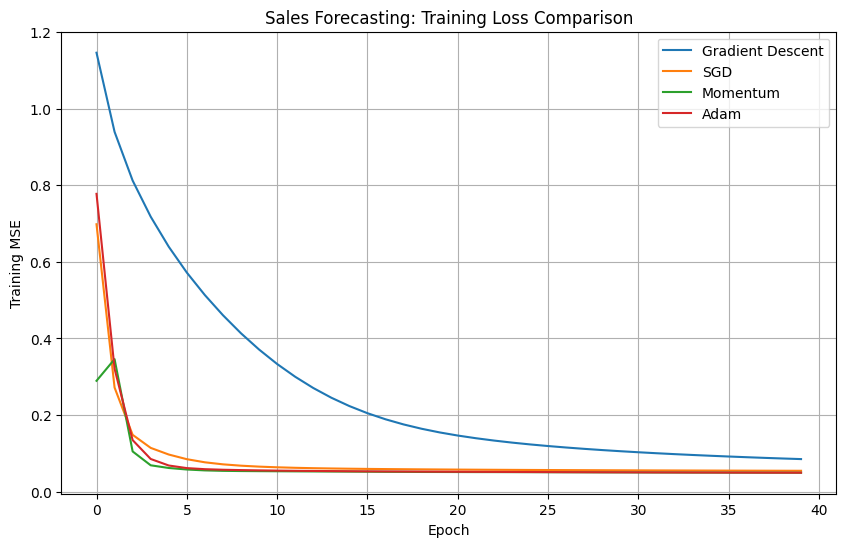

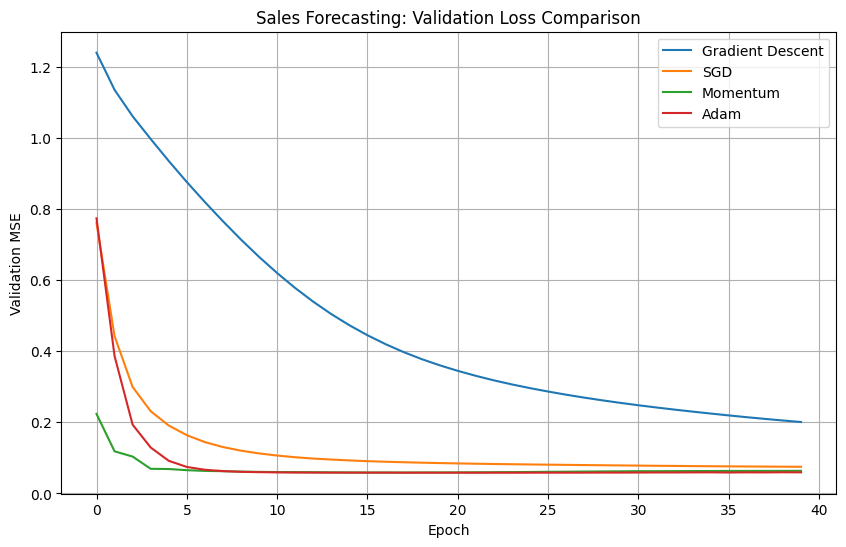


FINAL OPTIMIZER COMPARISON
--------------------------------------------------------------------
Optimizer              Train MSE     Val MSE     Val MAE
--------------------------------------------------------------------
Gradient Descent          0.0851      0.2009      0.3715
SGD                       0.0546      0.0750      0.2196
Momentum                  0.0495      0.0637      0.2026
Adam                      0.0496      0.0594      0.1930

Lowest final validation loss: Adam
Validation MSE: 0.0594
Validation MAE: 0.193


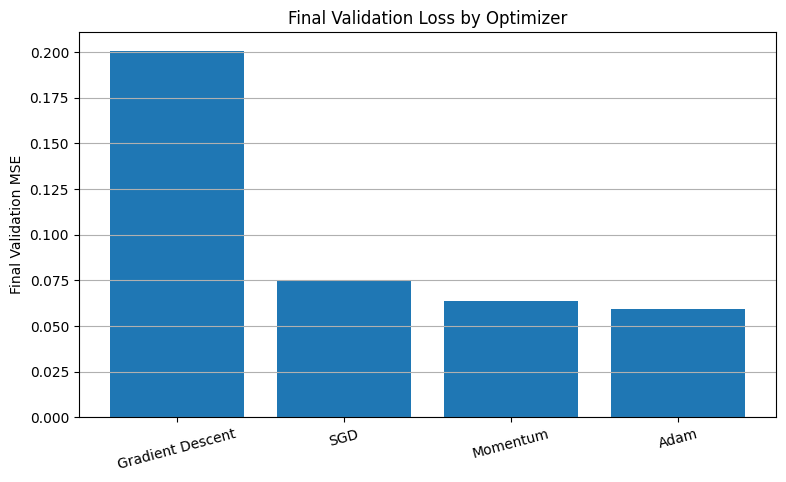

In [ ]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

n = 1500
week = np.arange(n)

advertising = np.random.uniform(100, 1000, n)
price = np.random.uniform(10, 100, n)
seasonality = np.sin(2 * np.pi * week / 52)
trend = week / n

X = np.column_stack((
    advertising, price, seasonality, trend
)).astype("float32")

sales = (
    200 + 0.4 * advertising - 1.5 * price
    + 80 * seasonality + 100 * trend
    + np.random.normal(0, 30, n)
).astype("float32")


X = (X - X.mean(axis=0)) / X.std(axis=0)
sales_mean = sales.mean()
sales_std = sales.std()
y = ((sales - sales_mean) / sales_std).astype("float32")

X_train, X_val = X[:1200], X[1200:]
y_train, y_val = y[:1200], y[1200:]

def build_model():
    return keras.Sequential([
        keras.Input(shape=(4,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1)
    ])

base = build_model()
initial_weights = base.get_weights()


optimizer_configs = {
    "Gradient Descent": (
        lambda: keras.optimizers.SGD(learning_rate=0.05),
        len(X_train)
    ),
    "SGD": (
        lambda: keras.optimizers.SGD(learning_rate=0.01),
        32
    ),
    "Momentum": (
        lambda: keras.optimizers.SGD(
            learning_rate=0.01, momentum=0.9
        ),
        32
    ),
    "Adam": (
        lambda: keras.optimizers.Adam(learning_rate=0.001),
        32
    )
}

histories = {}
models = {}


for name, (optimizer_fn, batch_size) in optimizer_configs.items():
    tf.random.set_seed(42)

    model = build_model()
    model.set_weights(initial_weights)

    model.compile(
        optimizer=optimizer_fn(),
        loss="mse",
        metrics=["mae"]
    )

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=batch_size,
        shuffle=False,
        verbose=0
    )

    models[name] = model
    histories[name] = {
        "train_loss": np.array(history.history["loss"]),
        "val_loss": np.array(history.history["val_loss"]),
        "train_mae": np.array(history.history["mae"]),
        "val_mae": np.array(history.history["val_mae"])
    }

    print(f"{name}: Training complete")

plt.figure(figsize=(10, 6))
for name, history in histories.items():
    plt.plot(history["train_loss"], label=name)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Sales Forecasting: Training Loss Comparison")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
for name, history in histories.items():
    plt.plot(history["val_loss"], label=name)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Sales Forecasting: Validation Loss Comparison")
plt.legend()
plt.grid(True)
plt.show()


names = list(histories.keys())
train_final = np.array([
    histories[name]["train_loss"][-1] for name in names
])
val_final = np.array([
    histories[name]["val_loss"][-1] for name in names
])
val_mae = np.array([
    histories[name]["val_mae"][-1] for name in names
])

print("\nFINAL OPTIMIZER COMPARISON")
print("-" * 68)
print(f"{'Optimizer':<20}{'Train MSE':>12}"
      f"{'Val MSE':>12}{'Val MAE':>12}")
print("-" * 68)

for i, name in enumerate(names):
    print(f"{name:<20}{train_final[i]:>12.4f}"
          f"{val_final[i]:>12.4f}{val_mae[i]:>12.4f}")

best_index = np.argmin(val_final)
print("\nLowest final validation loss:", names[best_index])
print("Validation MSE:", round(float(val_final[best_index]), 4))
print("Validation MAE:", round(float(val_mae[best_index]), 4))

plt.figure(figsize=(9, 5))
plt.bar(names, val_final)
plt.ylabel("Final Validation MSE")
plt.title("Final Validation Loss by Optimizer")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.show()
